In [18]:
import detectron2

In [23]:
from detectron2.data.datasets import register_coco_instances
from detectron2.data import MetadataCatalog, DatasetCatalog

for dataset_name in ["Car", "Bike"]:
    if dataset_name in DatasetCatalog.list():
        DatasetCatalog.remove(dataset_name)
        MetadataCatalog.remove(dataset_name)
        
register_coco_instances("Car", {}, 
                        "LicensePlateData/Initial_annotated_data/Car/annotations/car_instances_default.json", 
                        "LicensePlateData/Initial_annotated_data/Car/images")


register_coco_instances("Bike", {}, 
                        "LicensePlateData/Initial_annotated_data/Bike/annotations/bike_instances_default.json", 
                        "LicensePlateData/Initial_annotated_data/Bike/images")

car_metadata = MetadataCatalog.get("Car")
bike_metadata = MetadataCatalog.get("Bike")
print(car_metadata)
print(bike_metadata)


Metadata(name='Car', json_file='LicensePlateData/Initial_annotated_data/Car/annotations/car_instances_default.json', image_root='LicensePlateData/Initial_annotated_data/Car/images', evaluator_type='coco')
Metadata(name='Bike', json_file='LicensePlateData/Initial_annotated_data/Bike/annotations/bike_instances_default.json', image_root='LicensePlateData/Initial_annotated_data/Bike/images', evaluator_type='coco')


In [24]:
print(DatasetCatalog.list())

['coco_2014_train', 'coco_2014_val', 'coco_2014_minival', 'coco_2014_valminusminival', 'coco_2017_train', 'coco_2017_val', 'coco_2017_test', 'coco_2017_test-dev', 'coco_2017_val_100', 'keypoints_coco_2014_train', 'keypoints_coco_2014_val', 'keypoints_coco_2014_minival', 'keypoints_coco_2014_valminusminival', 'keypoints_coco_2017_train', 'keypoints_coco_2017_val', 'keypoints_coco_2017_val_100', 'coco_2017_train_panoptic_separated', 'coco_2017_train_panoptic_stuffonly', 'coco_2017_train_panoptic', 'coco_2017_val_panoptic_separated', 'coco_2017_val_panoptic_stuffonly', 'coco_2017_val_panoptic', 'coco_2017_val_100_panoptic_separated', 'coco_2017_val_100_panoptic_stuffonly', 'coco_2017_val_100_panoptic', 'lvis_v1_train', 'lvis_v1_val', 'lvis_v1_test_dev', 'lvis_v1_test_challenge', 'lvis_v0.5_train', 'lvis_v0.5_val', 'lvis_v0.5_val_rand_100', 'lvis_v0.5_test', 'lvis_v0.5_train_cocofied', 'lvis_v0.5_val_cocofied', 'cityscapes_fine_instance_seg_train', 'cityscapes_fine_sem_seg_train', 'citysca

Manual bounding box visualisation

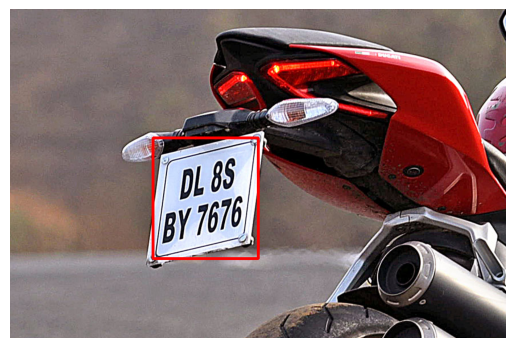

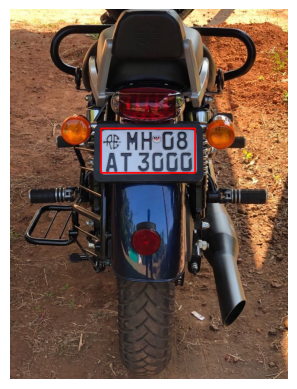

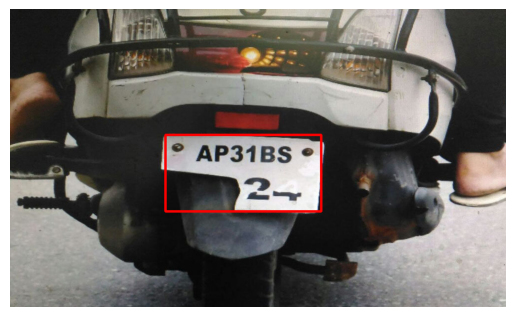

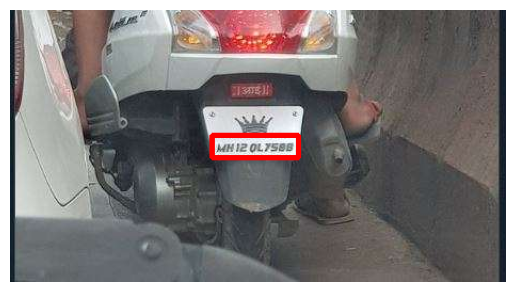

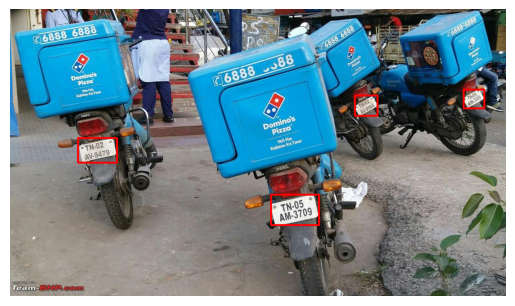

...

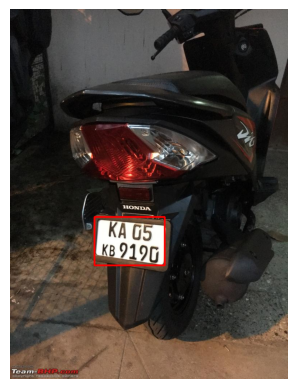

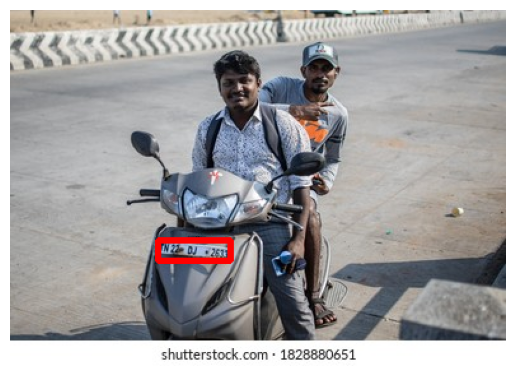

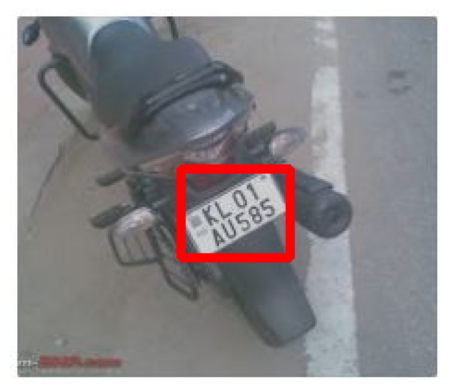

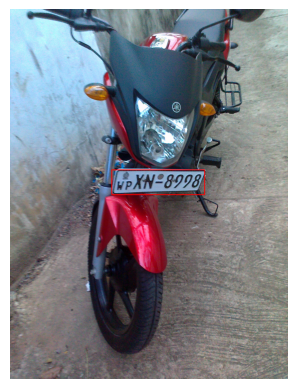

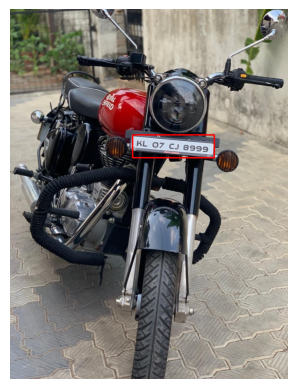

In [36]:
import json
import cv2
import matplotlib.pyplot as plt
import os

def load_annotations(json_path):
    with open(json_path, "r") as f:
        annotations = json.load(f)
    return annotations

def visualize_bbox(image_path, bboxes):
    if not os.path.exists(image_path):
        print(f"Image not found: {image_path}")
        return
    
    img = cv2.imread(image_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    for bbox in bboxes:
        x_min, y_min, width, height = bbox
        x_max = x_min + width
        y_max = y_min + height

        cv2.rectangle(img, (int(x_min), int(y_min)), (int(x_max), int(y_max)), (255, 0, 0), 3)

    plt.imshow(img)
    plt.axis("off")
    plt.show()

def main(json_path, image_folder):
    data = load_annotations(json_path)
    
    image_id_to_filename = {img["id"]: img["file_name"] for img in data["images"]}

    image_bboxes = {}
    for ann in data["annotations"]:
        image_id = ann["image_id"]
        bbox = ann["bbox"]
        
        if image_id in image_id_to_filename:
            file_name = image_id_to_filename[image_id]
            if file_name not in image_bboxes:
                image_bboxes[file_name] = []
            image_bboxes[file_name].append(bbox)

    for file_name, bboxes in image_bboxes.items():
        image_path = os.path.join(image_folder, file_name)
        visualize_bbox(image_path, bboxes)

json_path = "LicensePlateData/Initial_annotated_data/Bike/annotations/bike_instances_default.json"  
image_folder = "LicensePlateData/Initial_annotated_data/Bike/images" 
main(json_path, image_folder)


Checking annotations

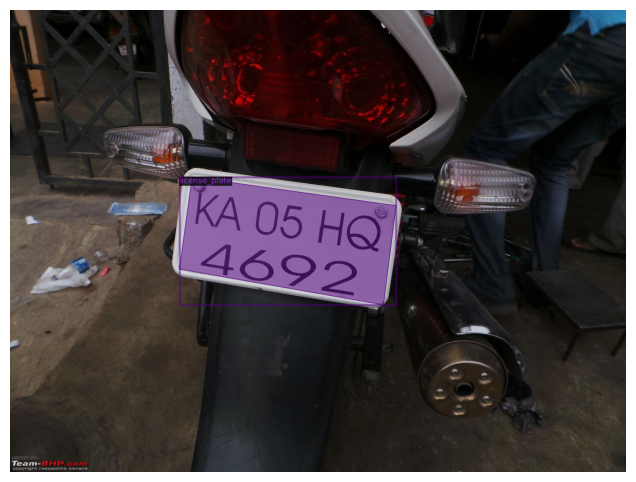

In [41]:
import cv2
import random
import matplotlib.pyplot as plt
from detectron2.utils.visualizer import Visualizer

dataset_dicts = DatasetCatalog.get("Bike")  

sample = random.choice(dataset_dicts)

img = cv2.imread(sample["file_name"])
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

visualizer = Visualizer(img, metadata=bike_metadata, scale=1.0)
vis = visualizer.draw_dataset_dict(sample)

plt.figure(figsize=(10, 6))
plt.imshow(vis.get_image())
plt.axis("off")
plt.show()


Bike Dataset - bounding box for other unannotated images.

In [49]:
import detectron2
from detectron2.engine import DefaultTrainer
from detectron2.config import get_cfg
from detectron2.data import MetadataCatalog, DatasetCatalog
from detectron2.model_zoo import get_config_file

cfg = get_cfg()
cfg.merge_from_file(get_config_file("COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml")) # Pre-trained model
cfg.DATASETS.TRAIN = ("Bike",)  
cfg.DATASETS.TEST = ()
cfg.MODEL.DEVICE = "cpu"
cfg.DATALOADER.NUM_WORKERS=4
cfg.SOLVER.IMS_PER_BATCH = 2
cfg.SOLVER.BASE_LR = 0.00025  
cfg.SOLVER.MAX_ITER = 2500  
cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE = 128
cfg.MODEL.ROI_HEADS.NUM_CLASSES = 1  
cfg.OUTPUT_DIR = "./detectron2_output"

os.makedirs(cfg.OUTPUT_DIR, exist_ok=True)
trainer = DefaultTrainer(cfg)
trainer.resume_or_load(resume=False)
trainer.train()

[02/22 16:13:28 d2.engine.defaults]: Model:
GeneralizedRCNN(
  (backbone): FPN(
    (fpn_lateral2): Conv2d(256, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral3): Conv2d(512, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output3): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral4): Conv2d(1024, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output4): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral5): Conv2d(2048, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output5): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (top_block): LastLevelMaxPool()
    (bottom_up): ResNet(
      (stem): BasicStem(
        (conv1): Conv2d(
          3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False
          (norm): FrozenBatchNorm2d(num_features=64, eps=1e-05)
        )
      )
      (res

Some model parameters or buffers are not found in the checkpoint:
backbone.fpn_lateral2.{bias, weight}
backbone.fpn_lateral3.{bias, weight}
backbone.fpn_lateral4.{bias, weight}
backbone.fpn_lateral5.{bias, weight}
backbone.fpn_output2.{bias, weight}
backbone.fpn_output3.{bias, weight}
backbone.fpn_output4.{bias, weight}
backbone.fpn_output5.{bias, weight}
proposal_generator.rpn_head.anchor_deltas.{bias, weight}
proposal_generator.rpn_head.conv.{bias, weight}
proposal_generator.rpn_head.objectness_logits.{bias, weight}
roi_heads.box_head.fc1.{bias, weight}
roi_heads.box_head.fc2.{bias, weight}
roi_heads.box_predictor.bbox_pred.{bias, weight}
roi_heads.box_predictor.cls_score.{bias, weight}
roi_heads.mask_head.deconv.{bias, weight}
roi_heads.mask_head.mask_fcn1.{bias, weight}
roi_heads.mask_head.mask_fcn2.{bias, weight}
roi_heads.mask_head.mask_fcn3.{bias, weight}
roi_heads.mask_head.mask_fcn4.{bias, weight}
roi_heads.mask_head.predictor.{bias, weight}
The checkpoint state_dict contains 

[02/22 16:13:28 d2.engine.train_loop]: Starting training from iteration 0
[02/22 16:21:43 d2.utils.events]:  eta: 16:33:00  iter: 19  total_loss: 1.77  loss_cls: 0.3644  loss_box_reg: 0.0009455  loss_mask: 0.6927  loss_rpn_cls: 0.6955  loss_rpn_loc: 0.01585    time: 23.4972  last_time: 17.0211  data_time: 0.9475  last_data_time: 0.0097   lr: 4.9953e-06  
[02/22 16:28:54 d2.utils.events]:  eta: 15:22:56  iter: 39  total_loss: 1.563  loss_cls: 0.1776  loss_box_reg: 0.0008759  loss_mask: 0.6849  loss_rpn_cls: 0.6859  loss_rpn_loc: 0.008877    time: 22.4926  last_time: 20.5592  data_time: 0.0052  last_data_time: 0.0053   lr: 9.9902e-06  
[02/22 16:36:19 d2.utils.events]:  eta: 15:00:34  iter: 59  total_loss: 1.433  loss_cls: 0.08317  loss_box_reg: 0.0006252  loss_mask: 0.6652  loss_rpn_cls: 0.6669  loss_rpn_loc: 0.01079    time: 22.4053  last_time: 20.0424  data_time: 0.0062  last_data_time: 0.0093   lr: 1.4985e-05  
[02/22 16:43:21 d2.utils.events]:  eta: 14:39:48  iter: 79  total_loss: 1

: 